In [71]:
import sys

sys.path.append("/home/jovyan/practice/Bayesian-Stats-HS2026/my_solutions/")

print(sys.path)

['/opt/conda/lib/python313.zip', '/opt/conda/lib/python3.13', '/opt/conda/lib/python3.13/lib-dynload', '', '/home/jovyan/.local/lib/python3.13/site-packages', '/home/jovyan/practice/Bayesian-Stats-HS2026/course_tools/src', '/opt/conda/lib/python3.13/site-packages', '.', '.', '.', './', '/home/jovyan/practice/Bayesian-Stats-HS2026/my_solutions', '/home/jovyan/practice/Bayesian-Stats-HS2026/my_solutions', '/home/jovyan/practice/Bayesian-Stats-HS2026/my_solutions', '/home/jovyan/practice/Bayesian-Stats-HS2026/my_solutions', '/home/jovyan/practice/Bayesian-Stats-HS2026/my_solutions/', '/home/jovyan/practice/Bayesian-Stats-HS2026/my_solutions/']


In [79]:
title = "# Introduction to Bayesian statistics: exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)
import numpy as np
import matplotlib.style
import scipy
import pickle
import matplotlib.pyplot as plt
import emcee
import corner

# matplotlib.style.use("bayesian_stats_course_tools.light")
# matplotlib.rcParams['figure.figsize'] = [4, 2]

# Introduction to Bayesian statistics: exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

# Exercise 1

- Implement your own version of the line-fitting procedure, using the same data.
- Now try it with the data in `lectures/data/linear_fits/data_1.txt`
    - First plot the data. What has changed?
    - Try the same model and likelihood on the new data. You might want to adjust the prior on $m$ and $b$ for this new data set.
    - What if you use the provided uncertainty per data point $\sigma_{y_i}$, instead of assuming a constant variance $\sigma_y$ for all data points?
    - Instead use the actual likelihood of the data:
\begin{align}
    \mu(x) &= mx + b \\
    \sigma(x_i) &= \sigma_{y_i} + f\mu(x_i)^2 \quad f > 0\ \text{a parameter} \\
    y_i&\sim\mathcal N(\mu(x_i),\sigma(x_i)^2)
\end{align}
Careful with the normalisation of the Gaussian likelihood. Because we vary the variance, this matters now!

In [2]:
def model(m, b, x):
    return m*x + b

def log_likelihood_probability(y, m, b, x, sigma_y):
    prediction = model(m, b, x)

    #n = 1
    n = len(y)
    return(
        -0.5 * np.sum((y - prediction)**2/sigma_y**2)
        - n/2*np.log(2*np.pi*sigma_y**2)
    )

In [3]:
model(1, 0, 1)

1

In [7]:
m_prior = scipy.stats.norm(loc=-1, scale=1)
b_prior = scipy.stats.norm(loc=2, scale=1)

def log_prior_probability(m, b):
    return m_prior.logpdf(m) + b_prior.logpdf(b)

In [8]:
data_file = "/home/jovyan/practice/Bayesian-Stats-HS2026/lectures/data/linear_fits/data_1.txt"

x, y, y_err = np.loadtxt(data_file, unpack=True)

#plt.errorbar(x, y, y_err, linestyle="None", marker="o")

In [9]:
def sample_prior(n_sample):
    return np.vstack((m_prior.rvs(n_sample), b_prior.rvs(n_sample))).T

np.random.seed(42)

# Evaluate the model at the prior sample parameters
prior_model_predictive = np.array(
    [model(*parameters, x) for parameters in sample_prior(n_sample=20)]
)

In [10]:
def plot_linear_data_set(x, y, y_err=None):
    """Plot linear data set and format the plot."""
    fig, ax = plt.subplots(1, 1)

    if y_err is not None:
        ax.errorbar(x, y, y_err, fmt=".", label="Data")
    else:
        ax.plot(x, y, marker=".", linestyle="none", label="Data")

    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.legend(loc="upper left")

    return fig, ax

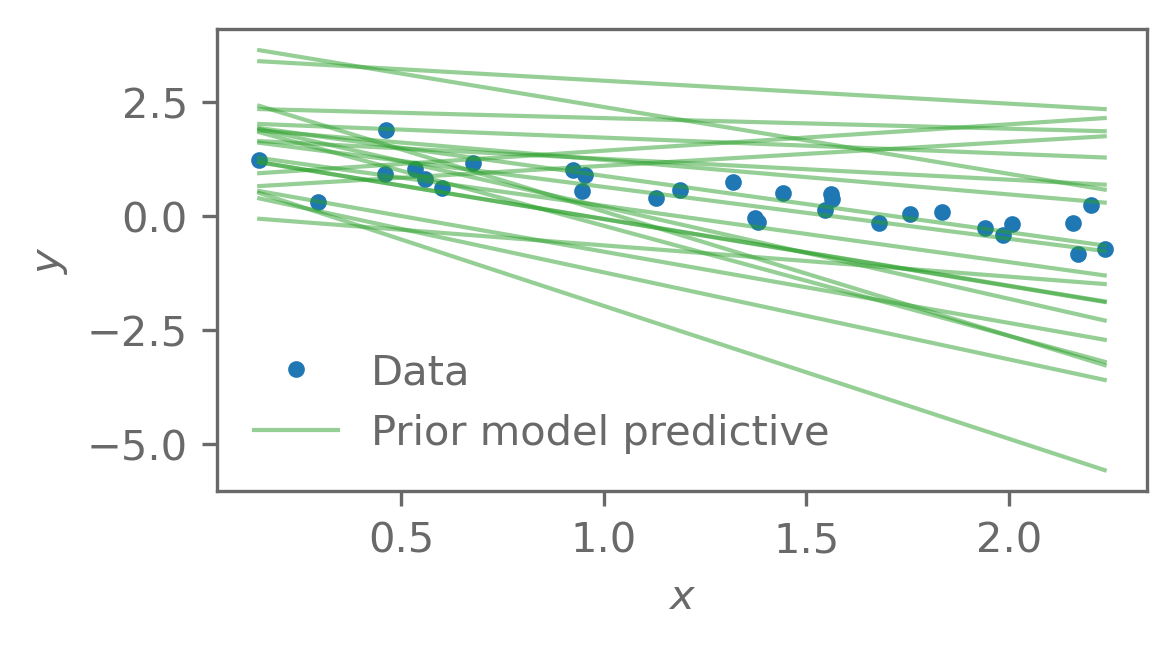

In [11]:
_, ax = plot_linear_data_set(x, y)

style = dict(c="C2", lw=1, alpha=0.5)
ax.plot(x, prior_model_predictive.T, **style)
ax.plot([], [], label="Prior model predictive", **style)
ax.legend();

In [12]:
def log_posterior_probability(m, b, x, sigma_y, y):
    return (
        log_likelihood_probability(y, m, b, x, sigma_y)
        + log_prior_probability(m, b)
    )

In [13]:
# The scipy minimizer finds the minimum, so we need to take the 
# negative of the posterior. The scipy minimizer also passes an array 
# with the parameters, this wrapper splits this array into m and b.
def negative_log_posterior(theta, x, sigma_y, y):
    m, b = theta
    return -log_posterior_probability(m, b, x, sigma_y, y)

sigma_y = 1

MAP_result = scipy.optimize.minimize(
    fun=negative_log_posterior,
    x0=(1, 0),
    args=(x, sigma_y, y)
)
m_MAP, b_MAP = MAP_result.x

print("MAP results")
print(f"m_MAP = {m_MAP:.3f}, b_MAP = {b_MAP:.3f}")

MAP results
m_MAP = -0.861, b_MAP = 1.503


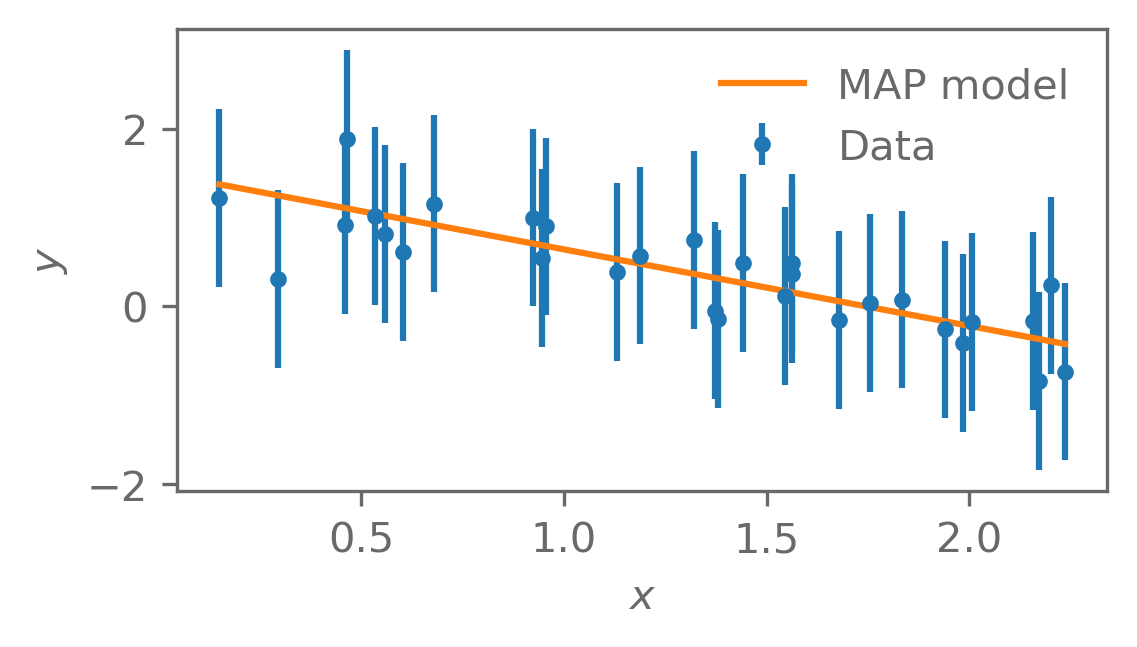

In [14]:
_, ax = plot_linear_data_set(x, y, sigma_y)

x_grid = np.linspace(0, 2.5, 100)
ax.plot(x, model(m_MAP, b_MAP, x), c="C1", label="MAP model")
ax.legend()

In [27]:
def log_likelihood_probability(theta, x, sigma_y, y):
    m, b, f = theta
    prediction = model(m, b, x)

    sigma = sigma_y + f*prediction**2

    n = len(y)
    return(
        -0.5 * np.sum((y - prediction)**2/sigma**2)
        - 0.5*np.sum(np.log(2*np.pi*sigma**2))
    )

In [21]:
def log_prior_probability(m, b):
    return m_prior.logpdf(m) + b_prior.logpdf(b)

In [19]:
def log_posterior_probability(theta, x, sigma_y, y):
    m, b, f = theta
    
    return (
        log_likelihood_probability(theta, x, sigma_y, y)
        + log_prior_probability(m, b)
    )

In [25]:
def negative_log_posterior(theta, x, sigma_y, y):
    return -log_posterior_probability(theta, x, sigma_y, y)

In [34]:
MAP_result = scipy.optimize.minimize(
    fun=negative_log_posterior,
    x0=(1, 0, 0),
    args=(x, sigma_y, y)
)
m_MAP, b_MAP, f_MAP = MAP_result.x

print("MAP results")
print(f"m_MAP = {m_MAP:.3f}, b_MAP = {b_MAP:.3f}")

MAP results
m_MAP = -0.749, b_MAP = 1.311


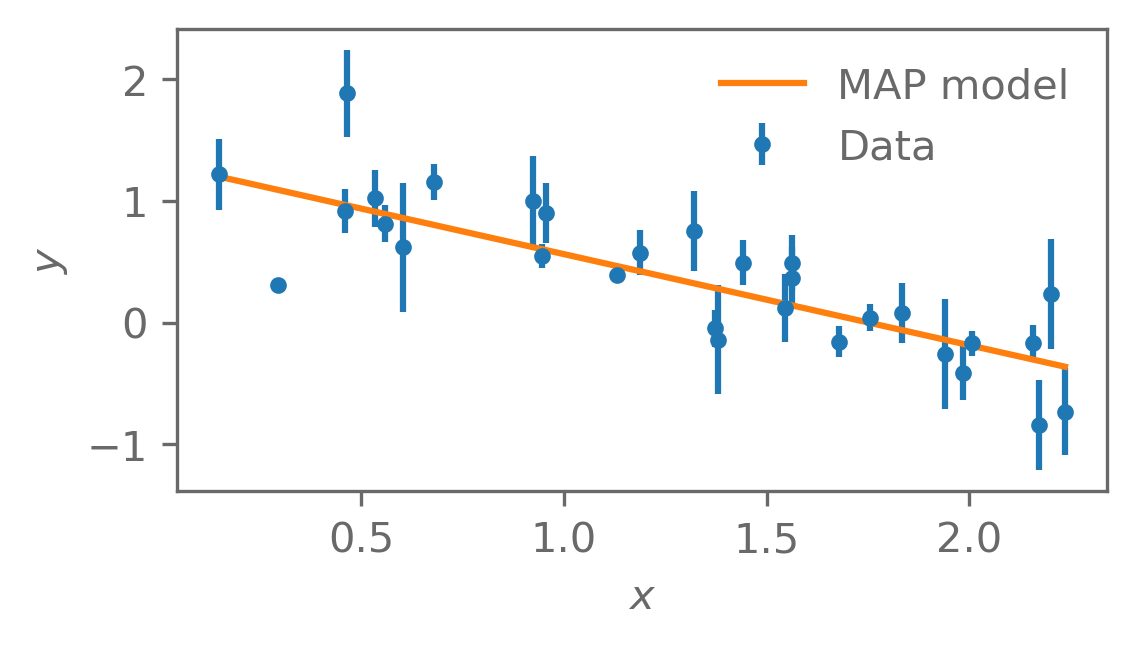

In [35]:
_, ax = plot_linear_data_set(x, y, sigma_y)

x_grid = np.linspace(0, 2.5, 100)
ax.plot(x, model(m_MAP, b_MAP, x), c="C1", label="MAP model")
ax.legend()

# Exercise 2

The data in the previous example were a synthetic version of real observations that were obtained in an AstroWoche project in 2024 by Jonas Spiller, Theo Lequy, Clara Bleich. 

<!-- ![jovian moons data](../assets/jovian_moons_raw_data.png) -->
<img style="display: block; 
    margin-left: auto;
    margin-right: auto;
    width: 60%;"
    src="../assets/jovian_moons_raw_data.png" alt="jovian moons data"/>

The real observations can be found in `data/jovian_moons/{moon}.dat`:

In [73]:
def plot_data(x, y, y_err, models=None, subtract_y=None,
              axis_labels=["$x$", "$y$"], **data_kwargs):
    """
    Create a set of summary plots for a list of "models."
    The types of plots are inferred from the dictionary
    describing the model.

    For example, if `violin_samples` is a key in the dictionary
    of one of the models, then a violinplot will be made, e.g.
    to visualize the posterior predictive distribution. 
    
    Parameters:
    -----------
    x : np.ndarray
        x-values of the data
    y : np.ndarray
        y-values of the data
    y_err : np.ndarray or float
        uncertainty on the y-values of the data
    models : list
        A list of models to plot information for. Each entry of this list
        is a dictionary that specifies information about the model. Below, we include
        the specification of what can be in this dictionary.
    subtract_y : np.ndarray or float
        An array of values or a single value to subtract 
        from all values of the data (a constant offset)
    axis_labels : list
        a list of strings, uses only the first two entries. The first for
        the x-axis the second for labeling the y-axis
    data_kwargs : dict
        a dictionary of keyword arguments that get passed to plotting functions
        like matplotlib.pyplot.plot.
        
    Returns:
    --------
    fig : plt.figure object
    ax : plt.axis object
    """

    
    fig, ax = plt.subplots()

    data_kwargs = {**data_kwargs}
    if "ls" not in data_kwargs and "linestyle" not in data_kwargs:
        data_kwargs["linestyle"] = "none"
    if "marker" not in data_kwargs:
        data_kwargs["marker"] = "."

    if subtract_y is None:
        subtract_y = np.zeros_like(y)
    ax.errorbar(x, y-subtract_y, y_err, **data_kwargs, label="Data")

    # set the width of the violin plots for the
    # posterior predictive plots
    def default_violin_width(x, scale=1.5, max_frac=0.1):
        """Violin width from mean x-spacing; overlap in clusters is tolerated."""
        x = np.unique(x)
        if x.size < 2:
            return 0.5
        span = x[-1] - x[0]
        return min(scale * span / (x.size - 1), max_frac * span)
        
    # loop 
    if models is not None:
        for model_def in models:
            if "lower" in model_def:
                ax.fill_between(
                    model_def["x"],
                    model_def["lower"], model_def["upper"],
                    **model_def.get("style", {})
                )
            elif "y_err" in model_def:
                ax.errorbar(
                    model_def["x"], model_def["y"], model_def["y_err"],
                    **model_def.get("style", {})
                )
            elif "violin_samples" in model_def:
                style = dict(model_def.get("style", {}))
                # pull apart what is a kwarg to ax.violinplot
                # and what has to be included separately
                # this is annoying because matplotlib's violinplots
                # are annoying.
                vp_kwargs = {k: style.pop(k) for k in
                             ("widths", "showmeans", "showmedians",
                              "showextrema", "quantiles", "points", "bw_method")
                             if k in style}
                vp_kwargs = {"showmeans": False, "showextrema": False, **vp_kwargs}
                vp_kwargs.setdefault("widths", default_violin_width(model_def["x"]))
                violin_plots = ax.violinplot(
                    dataset=model_def["violin_samples"],
                    positions=model_def["x"], **vp_kwargs
                )                
                for body in violin_plots["bodies"]:
                    body.set(**style)
                    if "label" in style:
                        del style["label"]

            else:
                ax.plot(
                    model_def["x"], model_def["y"],
                    **model_def.get("style", {})
                )

    ax.set_xlabel(axis_labels[0])
    ax.set_ylabel(axis_labels[1])
    ax.legend(frameon=False)

    return fig, ax

def analyse_data(data,
                 log_posterior_fn, model_fn, predict_fn, ppd_test_statistic_fn=None,
                 param_names=None,
                 derived_parameter_fn=None, derived_parameter_names=[],
                 derived_parameter_true=[],
                 theta_true=None,
                 theta_init=None, theta_init_std=None,
                 plot=True, model_x=None,
                 n_step_emcee=5000, n_ppd=500):
    """
    Implement a Bayesian workflow on 1-dimensional data that contains
    an independent variable (x), a dependent variable (y) and uncertainty
    on the measured dependent variable (y_err). 

    It first calculaes a maximum a posteriori value for the parameters using scipy.optimize.
    
    Then it uses Markov chain Monte Carlo to produce samples distributed according
    to the posterior distribution on the parameters of the model (using the 
    emcee package). 

    Subsequently, it calculates model predictive and posterior predictive distributions,
    plots them, and performs a posterior predictive check if there is a function
    that is supplied to do so (`ppd_test_statistic`, discussed in detail Week 7).

    Parameters:
    -----------
    log_posterior_fn : Callable function
        A callable function that takes in (theta, x, y_err, y) where
        theta is the list of free parameters.
    model_fn : Callable function
        A callable function that takes in (theta, x) as parameters
        and returns an estimate of y. 
    predict_fn : Callable function
        A callable function that takes in (theta, x, y_err, y) and produces
        predicted data from that model (simulates data from the likelihood, given
        a set of parameters).
    ppd_test_statistic_function : Callable function
        Takes in (y, theta, x, sigma_y) and produces a single summary statistic
        that can be used to compare replicated (posterior predictive) data with real data.
    derived_parameter_fn : Callable function
        If there are interesting parameters that are deterministically derived from the
        parameters that we sample, then they are defined here.
    derived_parameter_names : list
        A list of the names of the derived parameters output from `derived_parameter_fn`
    derived_parameter_true : list
        A list of the *true* derived parameters (if known)
    theta_true : np.ndarray, or list
        A list of the true parameters that were sampled (if known)
    theta_init : np.ndarray
        The initial values for the sampled parameters at the start of MCMC sampling
    theta_std : np.ndarray
        We can initialize the sampler around theta_init with some standard deviation.
    plot : bool
        True to make summary plots. False to not make them. 
    n_step_emcee : int, default=5000
        number of MCMC steps to take
    n_ppd : int, default=500
        number of posterior samples on which to calculate ppd_test_statistic

    Returns:
    --------
    results : dict
        A results dictionary containing samples, true values, posterior fit information
        and (if supplied) posterior predictive checking information.
    """

    x, y, sigma_y = data["x"], data["y"], data["y_err"]

    # MCMC initialization
    if theta_init is None:
        theta_init = theta_true
    theta_init = np.array(theta_init)

    if theta_init_std is None:
        theta_init_std = 0.1*theta_init
        theta_init_std[theta_init_std == 0.0] = 0.1

    # names of parameters
    if param_names is None:
        param_names = [f"p_{i}" for i in range(theta_init.size)]

    if model_x is None:
        model_x = x

    if theta_true is not None:
        true_model_plot_def = [dict(
            x=model_x, y=model_fn(theta_true, model_x),
            style=dict(color="black", ls="--", label="True model")
        )]
    else:
        true_model_plot_def = []

    # Find the MAP
    def negative_log_posterior(theta, x, sigma_y, y):
        return -log_posterior_fn(theta, x, sigma_y, y)

    MAP_result = scipy.optimize.minimize(
        fun=negative_log_posterior,
        x0=theta_init,
        args=(x, sigma_y, y)
    )
    theta_MAP = MAP_result.x

    print("MAP results")
    for name, theta in zip(param_names, theta_MAP):
        print(f"{name}_MAP = {theta}")


    # Sample posterior with emcee

    # emcee requires some extra settings to run
    n_param = len(theta_init) # Number of parameter we are sampling
    n_walker = 3*n_param      # Number of walkers. This just needs to be larger than 2*n_param + 1
    n_step = n_step_emcee     # How many steps each walker will take. The number of samples will be n_walker*n_step

    # The starting point for each walker
    theta_init = theta_init + theta_init_std*np.random.normal(size=(n_walker, n_param))

    # compute derived parameters while sampling
    if derived_parameter_fn is not None:
        log_posterior_wrapper = lambda *args: (log_posterior_fn(*args), derived_parameter_fn(args[0]))
    else:
        log_posterior_wrapper = log_posterior_fn
    sampler = emcee.EnsembleSampler(
        nwalkers=n_walker, ndim=n_param,
        log_prob_fn=log_posterior_wrapper,
        args=(x, sigma_y, y)
    )
    state = sampler.run_mcmc(theta_init, nsteps=n_step, progress=True)

    # The samples will be correlated, this checks how correlated they are
    # We will discuss this once we come to MCMC methods
    integrated_autocorr_time = sampler.get_autocorr_time(quiet=True)
    print("Auto-correlation time of chain:")
    for name, value in zip(param_names, integrated_autocorr_time):
        print(f"{name} = {value:.1f}")

    max_autocorr_time = max(integrated_autocorr_time)

    # We need to discard the beginning of the chain (a few auto-correlation times)
    # to get rid of the initial conditions
    burn_in_config = dict(
        discard=int(5*max_autocorr_time),
        thin=int(max_autocorr_time/2),
        flat=True
    )
    chain = sampler.get_chain(
        **burn_in_config
    )

    # Make predictive distributions
    # Choose a small subsample of the chain for plotting purposes
    chain_samples = chain[np.random.choice(chain.shape[0], size=n_ppd)]
    # Evaluate the model at the sample parameters
    model_predictive = np.array(
        [model_fn(sample, model_x) for sample in chain_samples]
    )
    model_quantiles = np.quantile(
        model_predictive, q=[0.025, 0.16, 0.84, 0.975], axis=0
    )

    posterior_predictive = np.array(
        [predict_fn(sample, x, sigma_y) for sample in chain_samples]
    )
    posterior_predictive_quantiles = np.quantile(
        posterior_predictive, q=[0.025, 0.16, 0.84, 0.975], axis=0
    )

    if ppd_test_statistic_fn is not None:
        T_rep = np.array(
            [ppd_test_statistic_fn(y_rep, sample, x, sigma_y)
             for y_rep, sample in zip(posterior_predictive, chain_samples)]
        )
        T_data = np.array(
            [ppd_test_statistic_fn(y, sample, x, sigma_y)
             for sample in chain_samples]
        )
        goodness_of_fit_pte = np.sum((T_rep - T_data) > 0)/len(T_rep)

        print(f"Posterior predictive p-value: {goodness_of_fit_pte:.2g} "
              f"(T_rep = {np.mean(T_rep):.2g}±{np.std(T_rep):.2g}, "
              f"T_data = {np.mean(T_data):.2g}±{np.std(T_data):.2g})"
        )

    if derived_parameter_fn is not None:
        blobs = sampler.get_blobs(
            **burn_in_config
        )
        if blobs.ndim == 1:
            blobs = blobs.reshape(-1, 1)
        chain = np.concatenate((chain, blobs), axis=-1)

    print("Posterior results (mean±std)")
    for i, name in enumerate(param_names + derived_parameter_names):
        print(f"{name} = {np.mean(chain[:,i]):.2g}±{np.std(chain[:,i]):.2g}")

    if plot:
        # Make a corner plot
        fig = plt.figure()
        fig = corner.corner(
            chain,
            bins=40,
            labels=param_names + derived_parameter_names,
            truths=theta_true + derived_parameter_true,
            levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding to 1 and 2 sigma in 2D
            quantiles=[0.025, 0.16, 0.84, 0.975],
            fig=fig
        )
        plot_data(
            x=x, y=y, y_err=sigma_y,
            models=[
                dict(x=model_x, y=model_fn(theta_MAP, model_x),
                    style=dict(color="C2", label="MAP model")),
                
                dict(x=model_x, lower=model_quantiles[0], upper=model_quantiles[-1],
                    style=dict(color="C1", alpha=0.5, label="Model predictions")),
                dict(x=model_x, lower=model_quantiles[1], upper=model_quantiles[-2],
                    style=dict(color="C1", alpha=0.5)),
                dict(x=x, violin_samples=posterior_predictive,
                     style=dict(color="grey", alpha=0.5, label="Posterior predictions")),
            ] + true_model_plot_def,
            marker=".", linestyle="none"
        )
        # plot our posterior predictive test statistic
        if ppd_test_statistic_fn is not None:
            fig = plt.figure(figsize=(6, 6))
            gs = fig.add_gridspec(2, 2, width_ratios=[2, 1], height_ratios=[1, 2],
                                  hspace=0.05, wspace=0.05)
            ax = fig.add_subplot(gs[1, 0])
            ax_top = fig.add_subplot(gs[0, 0], sharex=ax)
            ax_right = fig.add_subplot(gs[1, 1], sharey=ax)
        
            lims = [min(T_data.min(), T_rep.min()), max(T_data.max(), T_rep.max())]
            # edges = np.linspace(*lims, bins + 1)
        
            ax.scatter(T_data, T_rep, s=5, alpha=0.5)
            ax.plot(lims, lims, "k--", lw=1, label="$y = x$")
            ax.set_xlim(lims)
            ax.set_ylim(lims)
            ax.set_xlabel(r"$T(y, \theta)$")
            ax.set_ylabel(r"$T(y_\mathrm{rep}, \theta)$")
            ax.legend(frameon=False, loc="upper left")
        
            ax_top.hist(T_data, bins='auto', alpha=0.5)
            ax_right.hist(T_rep, bins='auto', alpha=0.5, orientation="horizontal")
            ax_top.tick_params(labelbottom=False)
            ax_right.tick_params(labelleft=False)
            ax_top.set_title(f"$p = {goodness_of_fit_pte:.2g}$")
            

    return dict(
        MAP=theta_MAP,
        PPD=posterior_predictive,
        TPD=model_predictive,
        PPD_params=chain_samples,
        chain=chain
    )

In [36]:
moon = "Europa"

t, distance, distance_alt, distance_err = np.loadtxt(
    f"/home/jovyan/practice/Bayesian-Stats-HS2026/lectures/data/jovian_moons/{moon}.dat", unpack=True)

1. Repeat the analysis with the real data set. What do you find?

There is another distance estimate provided. The difference between the distance estimates comes from different approaches to converting the measured distance between Jupiter and its moons from the number of pixels to a physical distance in km.

2. How does the analysis look when using this other distance estimate (what I call `distance_alt`)? What about the other moons?



Because there are two distance estimates that do not agree, both of which are based on reasonable approaches, this suggests that there might be a _systematic_ error in the measurements. Systematic errors are usually not random (which means they do not get smaller as you obtain more data). But we could pretend the offset between the two measurements is an estimate of an unaccounted statistical uncertainty. 

3. How does the analysis look when we assume `sigma_d**2 = distance_err**2 + (distance - distance_alt)**2`?



4. Instead of assuming that the uncertainty is underestimated by this offset, we can also model it. Does the model work better if the variance is a free parameter?


In [38]:
# Literature values
theta_true = dict(
    Io=[0.421700, 1.769*24, 2.935632897970926],
    Ganymede=[1.070400, 7.155*24, 1.5793369771861996],
    Europa=[0.671100, 3.551*24, 3.0779939041348796],
    Callisto=[1.882700, 16.689*24, 1.9374307501130097],
)

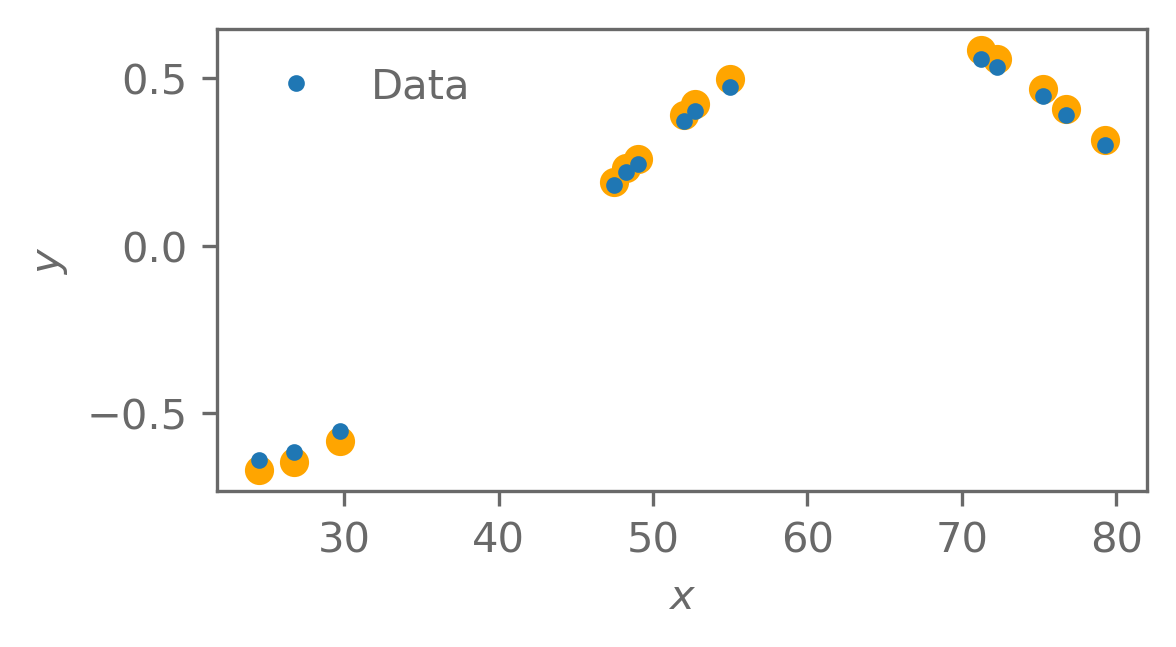

In [50]:
_, ax = plot_linear_data_set(t, distance_alt)
ax.scatter(t, distance, color='orange')

In [42]:
def build_inference_model(model_fn, log_prior_fn=None, variance_model_fn=None):
    # flat prior
    if log_prior_fn is None:
        log_prior_fn = lambda theta: 0
        
    # change the variance if a function is supplied
    # otherwise just return the square of the standard deviation
    # that is input
    if variance_model_fn is None:
        variance_model_fn = lambda sigma_y, theta, t: sigma_y**2
    
    def log_likelihood_fn(theta, t, sigma_y, y):
        # Gaussian log likelihood
        mu = model_fn(theta, t)
        sigma2 = variance_model_fn(sigma_y, theta, t)
        return -0.5*len(y)*np.log(2*np.pi) - 0.5*np.sum(np.log(sigma2)) - np.sum(0.5 * (y - mu)**2/sigma2)
    
    def log_posterior_fn(theta, t, sigma_y, y):
        # log posterior is log_likelihood + log_prior
        log_prior = log_prior_fn(theta)
        if not np.isfinite(log_prior):
            return -np.inf
        return log_likelihood_fn(theta, t, sigma_y, y) + log_prior

    def predict_fn(theta, x, sigma_y):
        # draw from our Gaussian likelihood
        # to produce new data, conditioned on 
        # a choice of parameters. 
        mu = model_fn(theta, x)
        sigma2 = variance_model_fn(sigma_y, theta, t)
        return np.random.normal(loc=mu, scale=np.sqrt(sigma2))

    def ppd_test_statistic_fn(y, theta, t, sigma_y):
        # Produce a summary statistic that is sensitive
        # to something we care about. In this case, overfitting. 
        # this is a simple chi^2 summary statistic. We will calculate this
        # on replicate data and on real data, across our posterior.
        mu = model_fn(theta, t)
        sigma2 = variance_model_fn(sigma_y, theta, t)
        return np.sum(0.5 * (y - mu)**2/sigma2)
    
    return log_posterior_fn, model_fn, predict_fn, ppd_test_statistic_fn

In [43]:
def base_model(theta, t):
    semimajor, period, phi = theta
    return semimajor * np.sin(2 * np.pi * t / period+phi)

MAP results
$a$_MAP = 0.6702865415084822
$T$_MAP = 84.07933307550036
$\phi$_MAP = 3.021881872509563


  0%|          | 0/5000 [00:00<?, ?it/s]

  3%|▎         | 155/5000 [00:00<00:03, 1546.59it/s]

  6%|▋         | 321/5000 [00:00<00:02, 1611.13it/s]

 10%|▉         | 483/5000 [00:00<00:03, 1350.09it/s]

...

 94%|█████████▎| 4681/5000 [00:03<00:00, 1403.62it/s]

 96%|█████████▋| 4822/5000 [00:03<00:00, 1403.54it/s]

 99%|█████████▉| 4963/5000 [00:03<00:00, 1391.41it/s]

100%|██████████| 5000/5000 [00:03<00:00, 1379.23it/s]

Auto-correlation time of chain:
$a$ = 47.8
$T$ = 51.5
$\phi$ = 51.2
Posterior predictive p-value: 0.98 (T_rep = 6.9±2.5, T_data = 1.9±1.1)
Posterior results (mean±std)
$a$ = 0.67±0.011
$T$ = 84±0.91
$\phi$ = 3±0.045
$M$ = 1.9e+27±1.2e+26


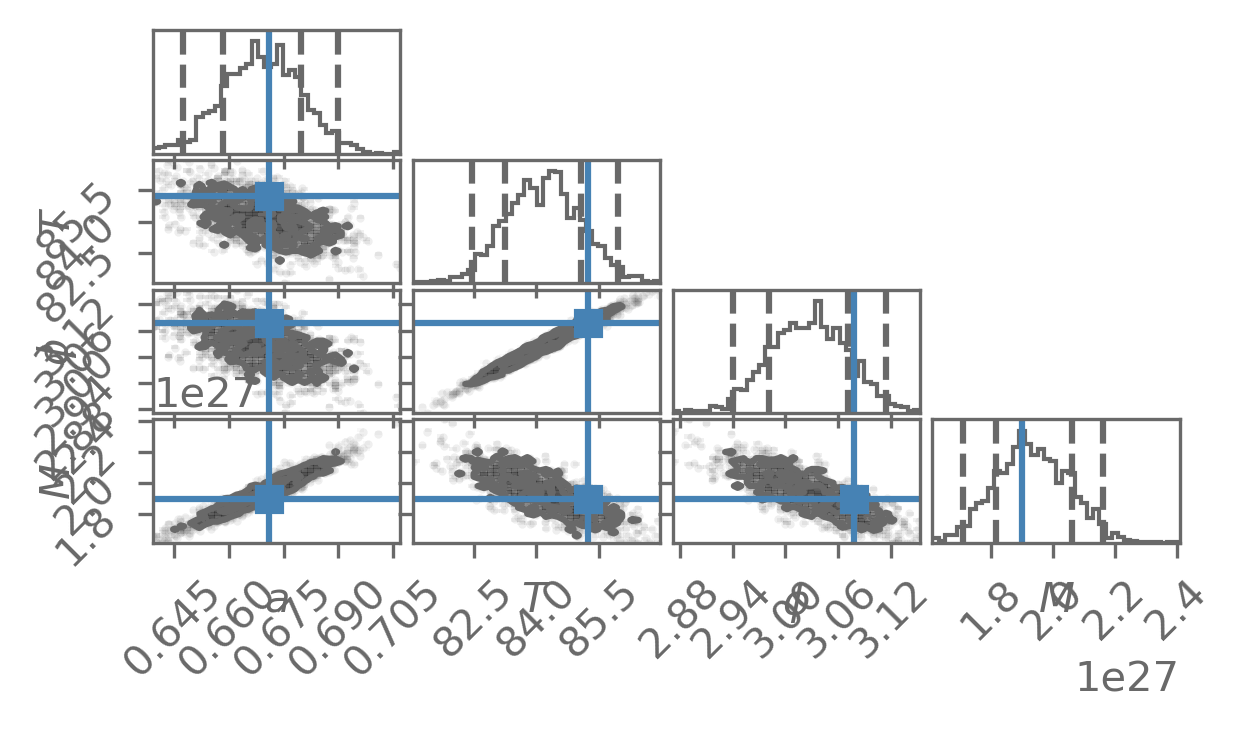

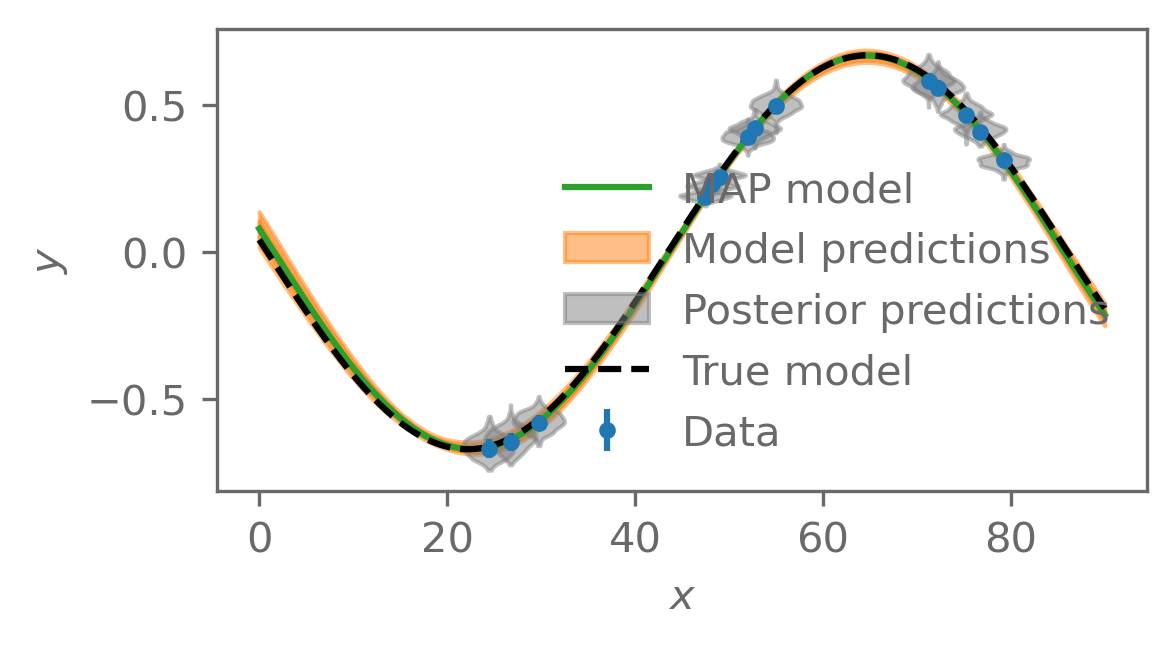

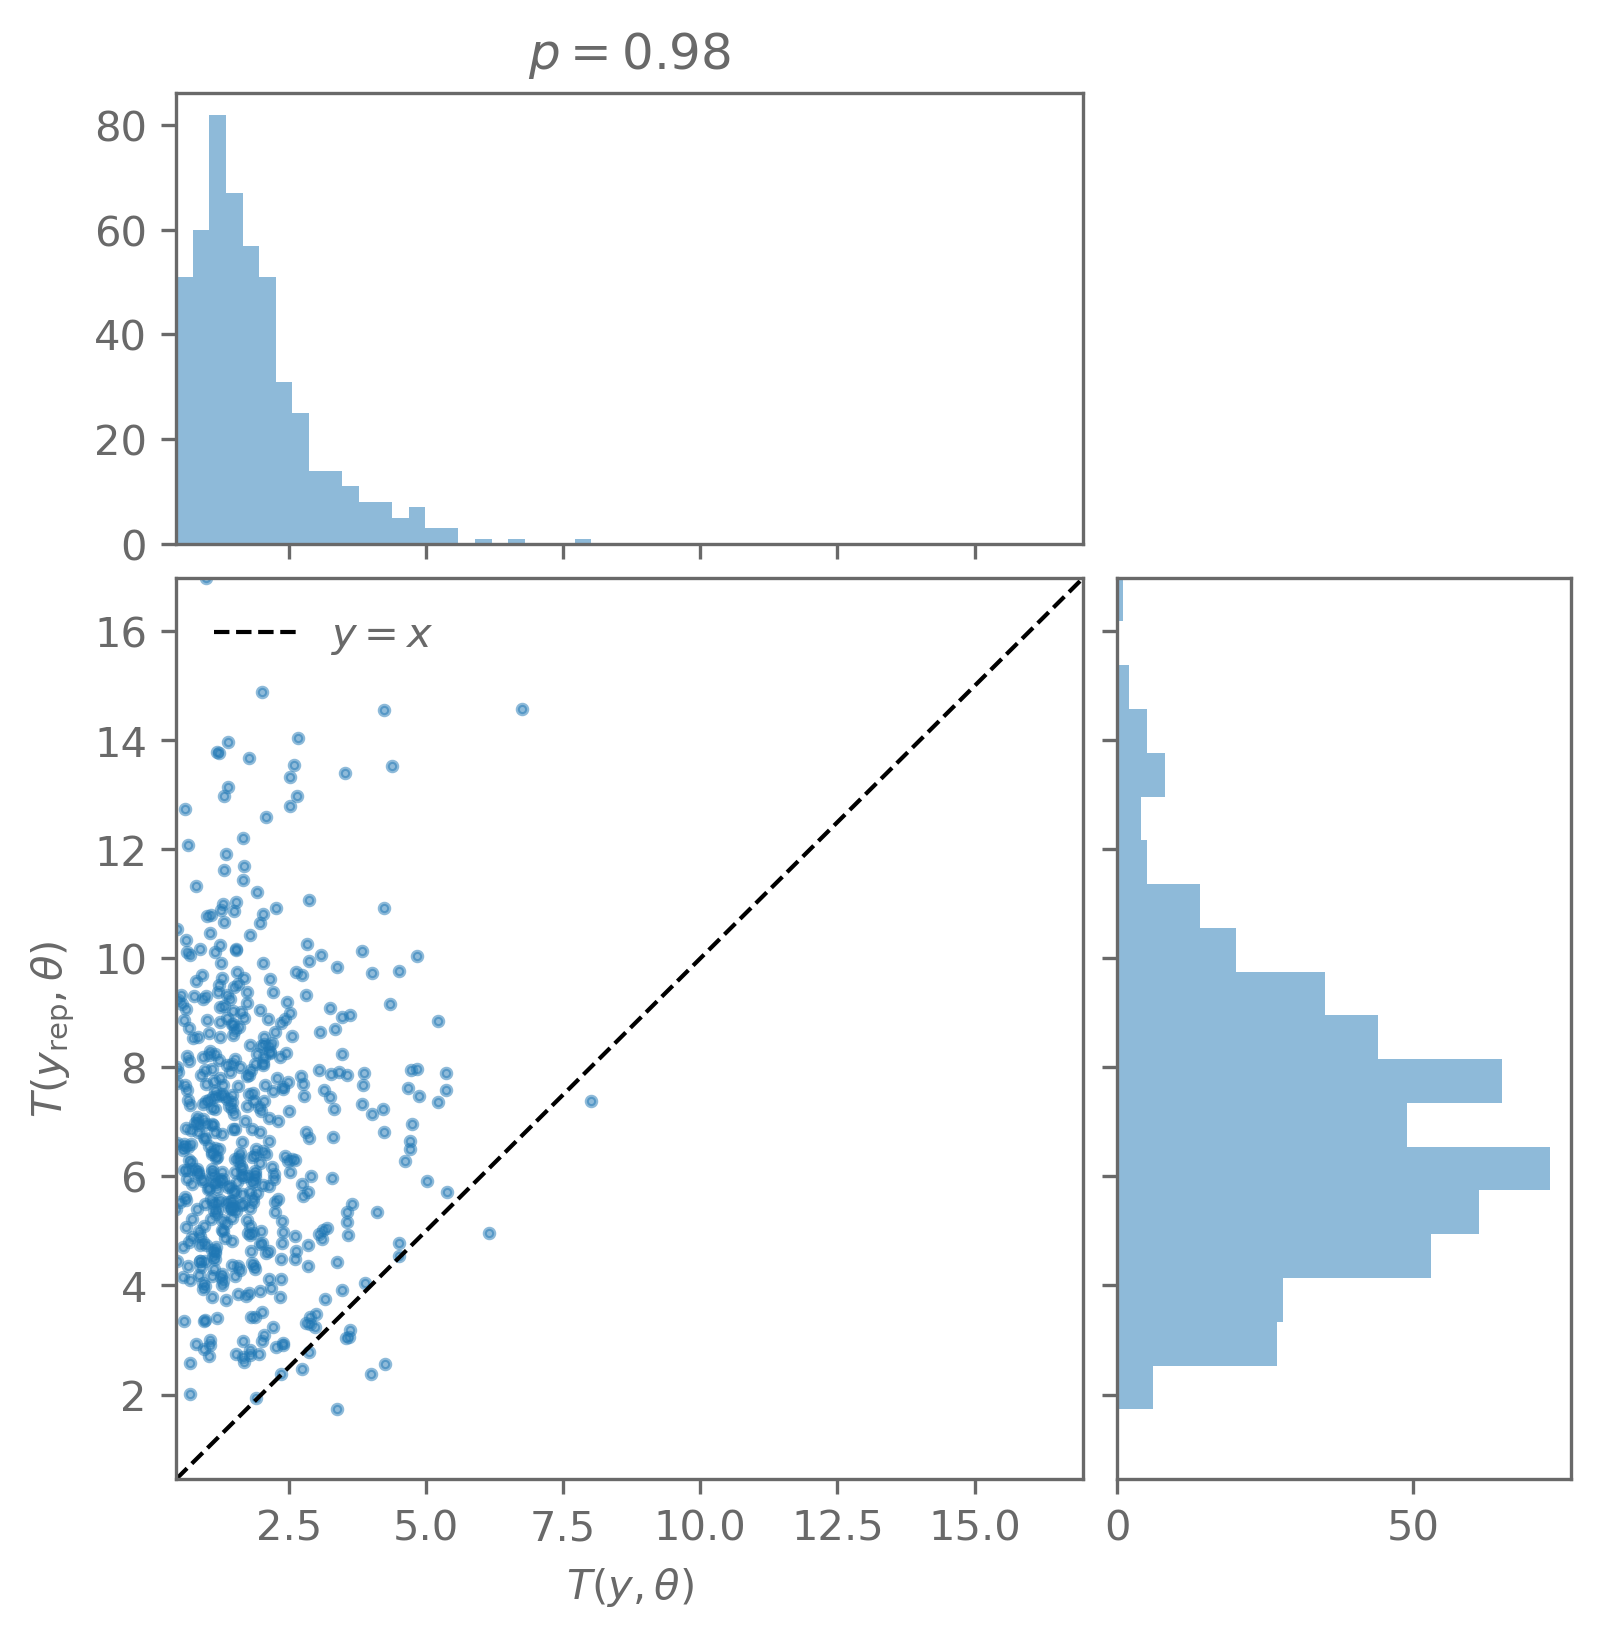

In [80]:
t_for_model = np.linspace(0, 90, 1000)

log_posterior, model, predict, ppd_test_statistic = build_inference_model(
    model_fn=base_model
)

# Inflate the uncertainty by the offset between the two distance estimates
distance_err_with_systematic = np.sqrt(distance_err**2 + (distance_alt-distance)**2)

data = dict(
    x=t, y=distance, y_err=distance_err_with_systematic
)

# derived parameter -- we want the mass based on the 
# measured semimajor axis and period. 
def mass_from_Kepler_3rd_law(theta):
    semimajor, period = theta[:2]
    return 4*(np.pi**2)/6.674e-11*((1e9*semimajor)**3)/((period*3600)**2)


results = analyse_data(
    data=data,
    log_posterior_fn=log_posterior,
    model_fn=model,
    predict_fn=predict,
    ppd_test_statistic_fn=ppd_test_statistic,
    param_names=["$a$", "$T$", "$\\phi$"],
    derived_parameter_fn=mass_from_Kepler_3rd_law,
    derived_parameter_names=["$M$"],
    derived_parameter_true=[1.8982e27],
    theta_true=theta_true[moon],
    theta_init=theta_true[moon],
    n_step_emcee=5000,
    model_x=t_for_model,
)

In [85]:
def sys_model(theta, t):
    semimajor, period, phi, a_sys = theta
    mu = base_model((semimajor, period, phi), t)
    return mu

def sys_variance_model(sigma_y, theta, t):
    # add our extra variance here. a_sys is a parameter, it lives in theta!
    semimajor, period, phi, a_sys = theta
    return sigma_y**2 + a_sys**2 

def log_sys_model_prior(theta):
    semimajor, period, phi, a_sys = theta
    if a_sys < 0:
        return -np.inf
    else:
        return 0.0

/opt/conda/lib/python3.13/site-packages/scipy/optimize/_numdiff.py:686: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]
/opt/conda/lib/python3.13/site-packages/scipy/optimize/_numdiff.py:686: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]


MAP results
$a$_MAP = 0.6710537222603429
$T$_MAP = 83.70965582068897
$\phi$_MAP = 3.0041422658303727
$a_\mathrm{sys}$_MAP = 0.0037699052277678255


  0%|          | 0/5000 [00:00<?, ?it/s]

  2%|▏         | 109/5000 [00:00<00:04, 1082.32it/s]

  4%|▍         | 218/5000 [00:00<00:05, 830.51it/s] 

...

 95%|█████████▌| 4763/5000 [00:04<00:00, 1086.72it/s]

 97%|█████████▋| 4873/5000 [00:04<00:00, 1019.52it/s]

100%|█████████▉| 4999/5000 [00:04<00:00, 1084.71it/s]

100%|██████████| 5000/5000 [00:04<00:00, 1037.23it/s]

Auto-correlation time of chain:
$a$ = 39.5
$T$ = 36.8
$\phi$ = 47.7
$a_\mathrm{sys}$ = 87.4
Posterior predictive p-value: 0.48 (T_rep = 6.9±2.6, T_data = 7.1±2.7)
Posterior results (mean±std)
$a$ = 0.67±0.0023
$T$ = 84±0.27
$\phi$ = 3±0.014
$a_\mathrm{sys}$ = 0.005±0.0015
$M$ = 2e+27±2.7e+25


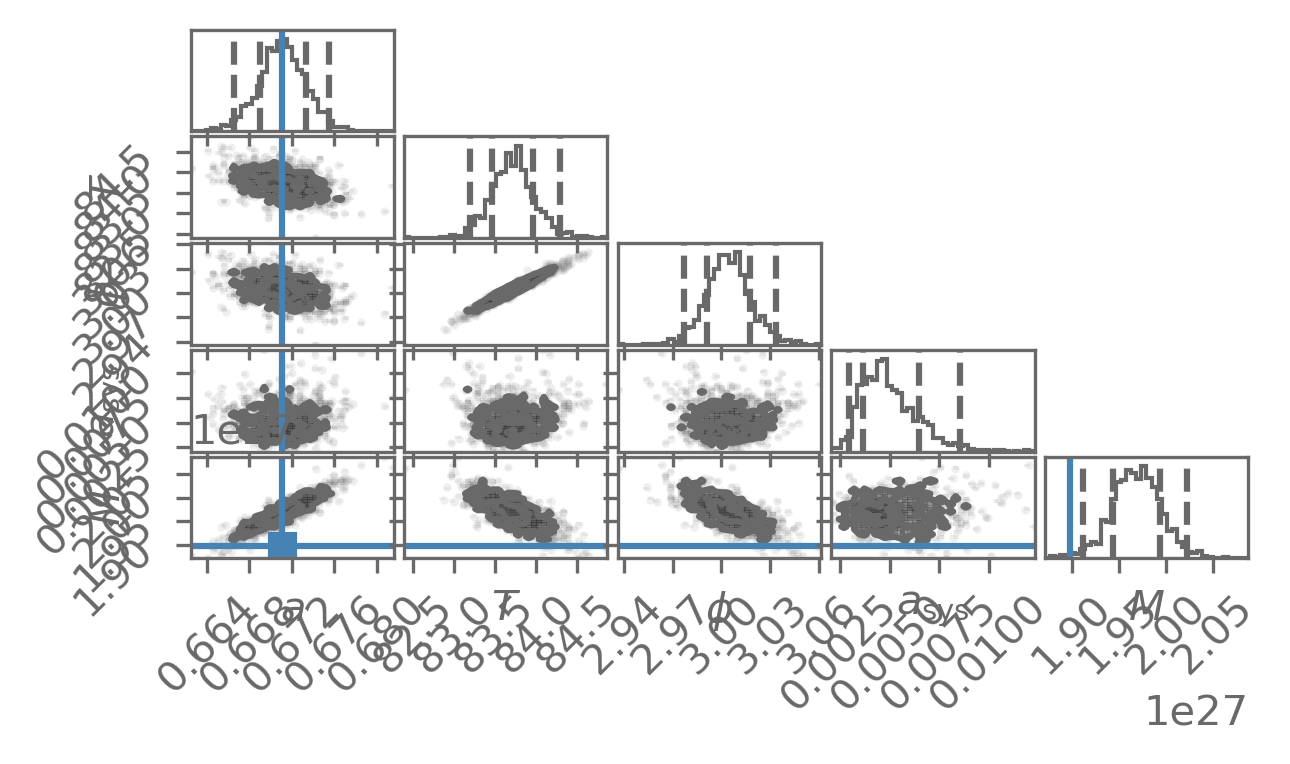

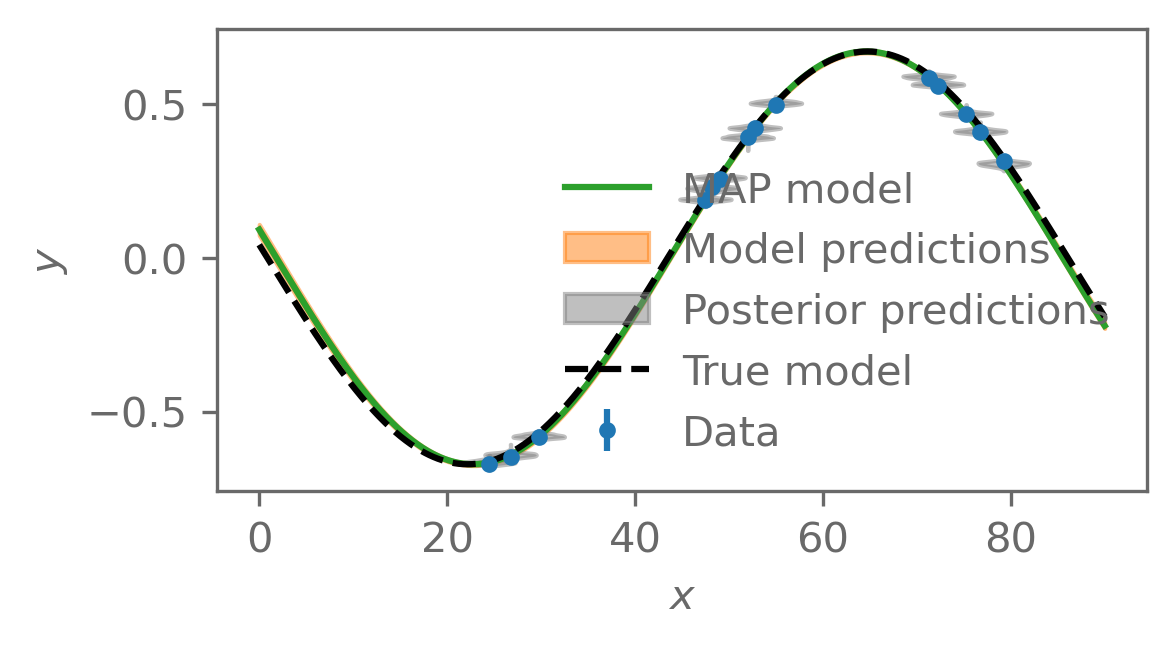

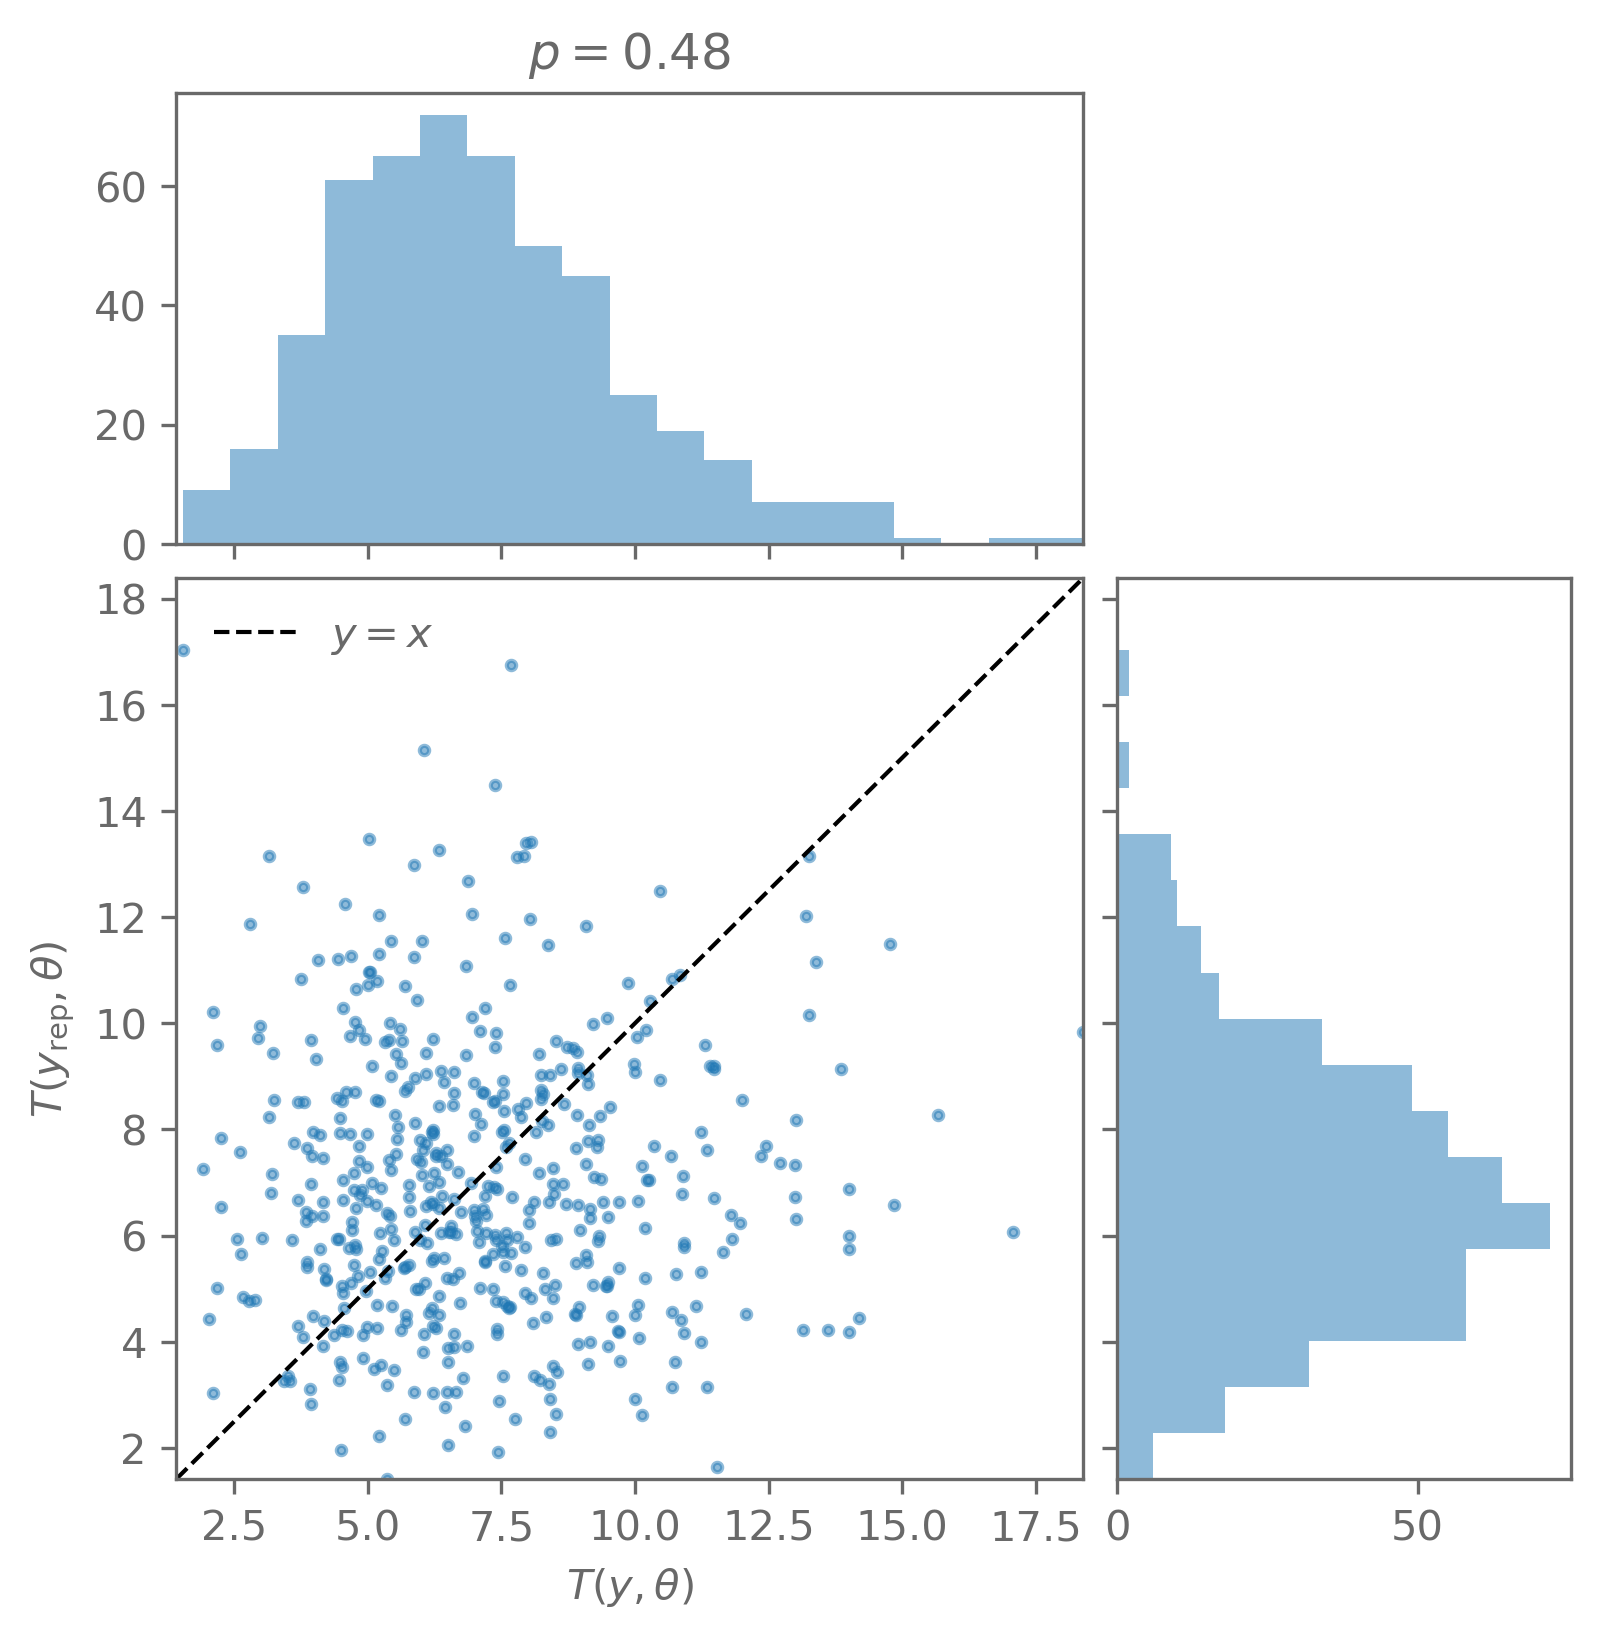

In [86]:
log_posterior, model, predict, ppd_test_statistic = build_inference_model(
    model_fn=sys_model, log_prior_fn=log_sys_model_prior, variance_model_fn=sys_variance_model
)

data = dict(
    x=t, y=distance, y_err=distance_err
)

results = analyse_data(
    data=data,
    log_posterior_fn=log_posterior,
    model_fn=model,
    predict_fn=predict,
    ppd_test_statistic_fn=ppd_test_statistic,
    param_names=["$a$", "$T$", "$\\phi$", "$a_\\mathrm{sys}$"],
    derived_parameter_fn=mass_from_Kepler_3rd_law,
    derived_parameter_names=["$M$"],
    derived_parameter_true=[1.8982e27],
    theta_true=theta_true[moon] + [None],
    theta_init=theta_true[moon] + [0.01],
    n_step_emcee=5000,
    model_x=t_for_model,
)

MAP results
$a$_MAP = 0.6392514619047499
$T$_MAP = 83.78283083883974
$\phi$_MAP = 3.0067867599721914


  0%|          | 0/5000 [00:00<?, ?it/s]

  3%|▎         | 151/5000 [00:00<00:03, 1508.76it/s]

  6%|▌         | 302/5000 [00:00<00:03, 1460.24it/s]

  9%|▉         | 449/5000 [00:00<00:03, 1355.61it/s]

...

 95%|█████████▍| 4744/5000 [00:03<00:00, 1137.48it/s]

 97%|█████████▋| 4865/5000 [00:03<00:00, 1079.61it/s]

100%|█████████▉| 4998/5000 [00:03<00:00, 1143.24it/s]

100%|██████████| 5000/5000 [00:03<00:00, 1300.31it/s]

Auto-correlation time of chain:
$a$ = 42.7
$T$ = 48.3
$\phi$ = 47.7
Posterior predictive p-value: 0.98 (T_rep = 7.1±2.5, T_data = 1.5±1.1)
Posterior results (mean±std)
$a$ = 0.64±0.04
$T$ = 84±5.1
$\phi$ = 3±0.26
$M$ = 1.7e+27±4.4e+26


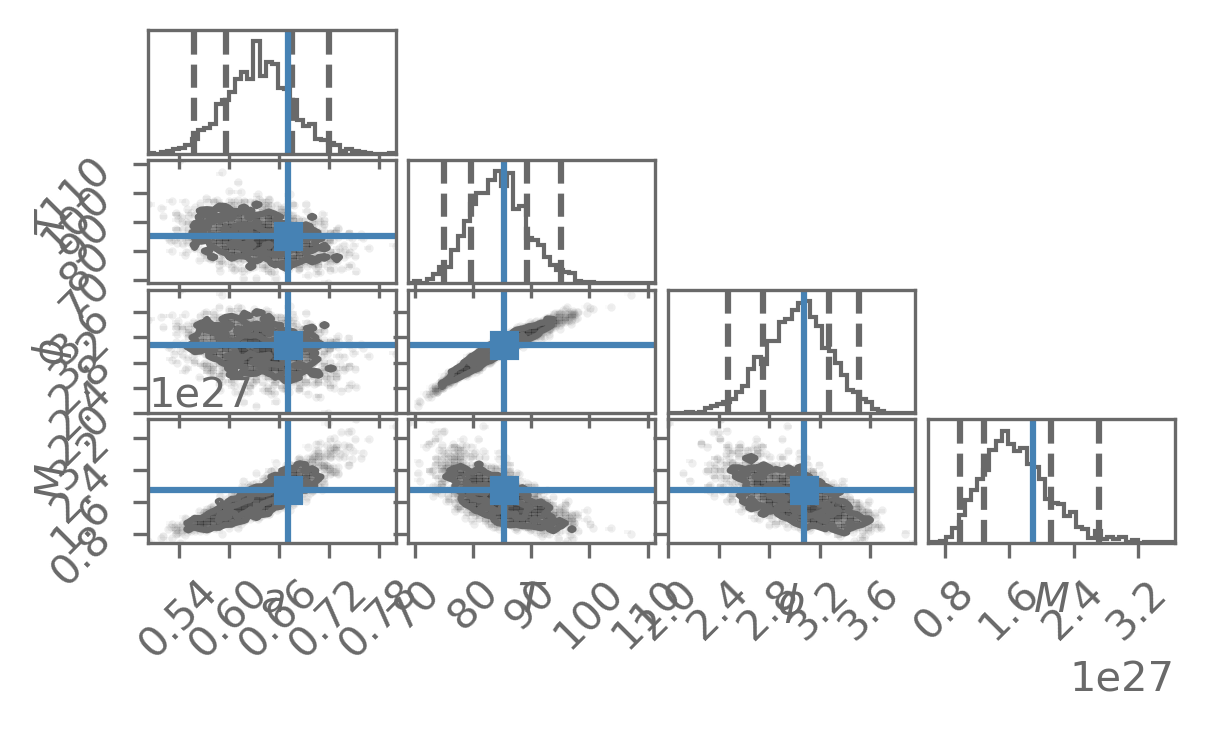

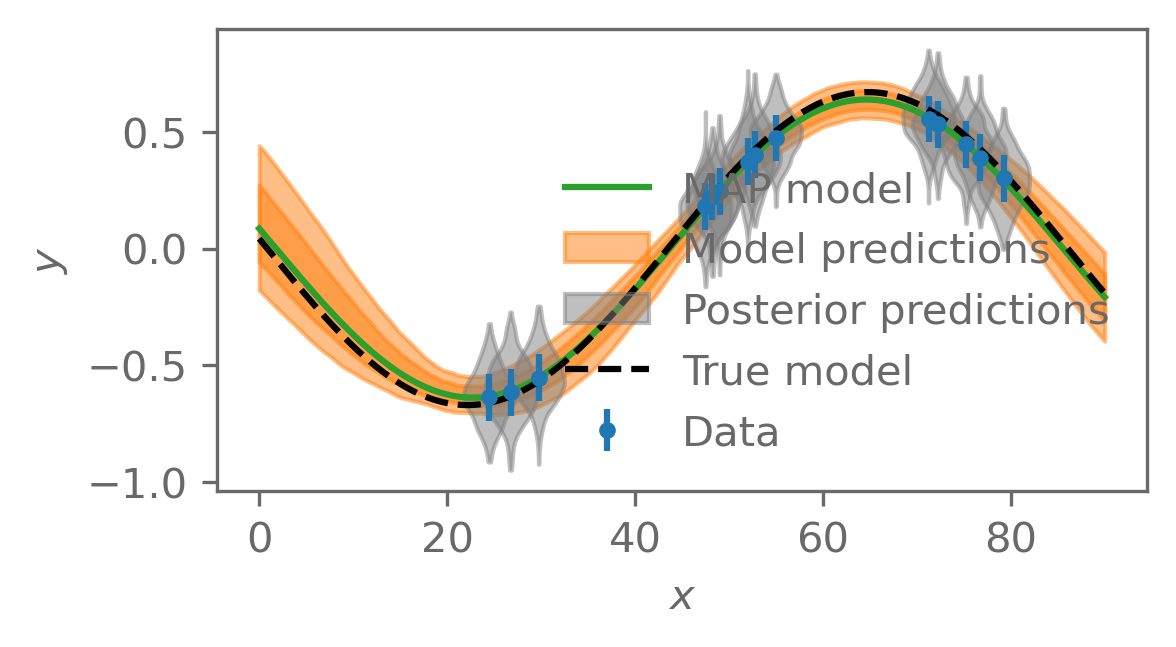

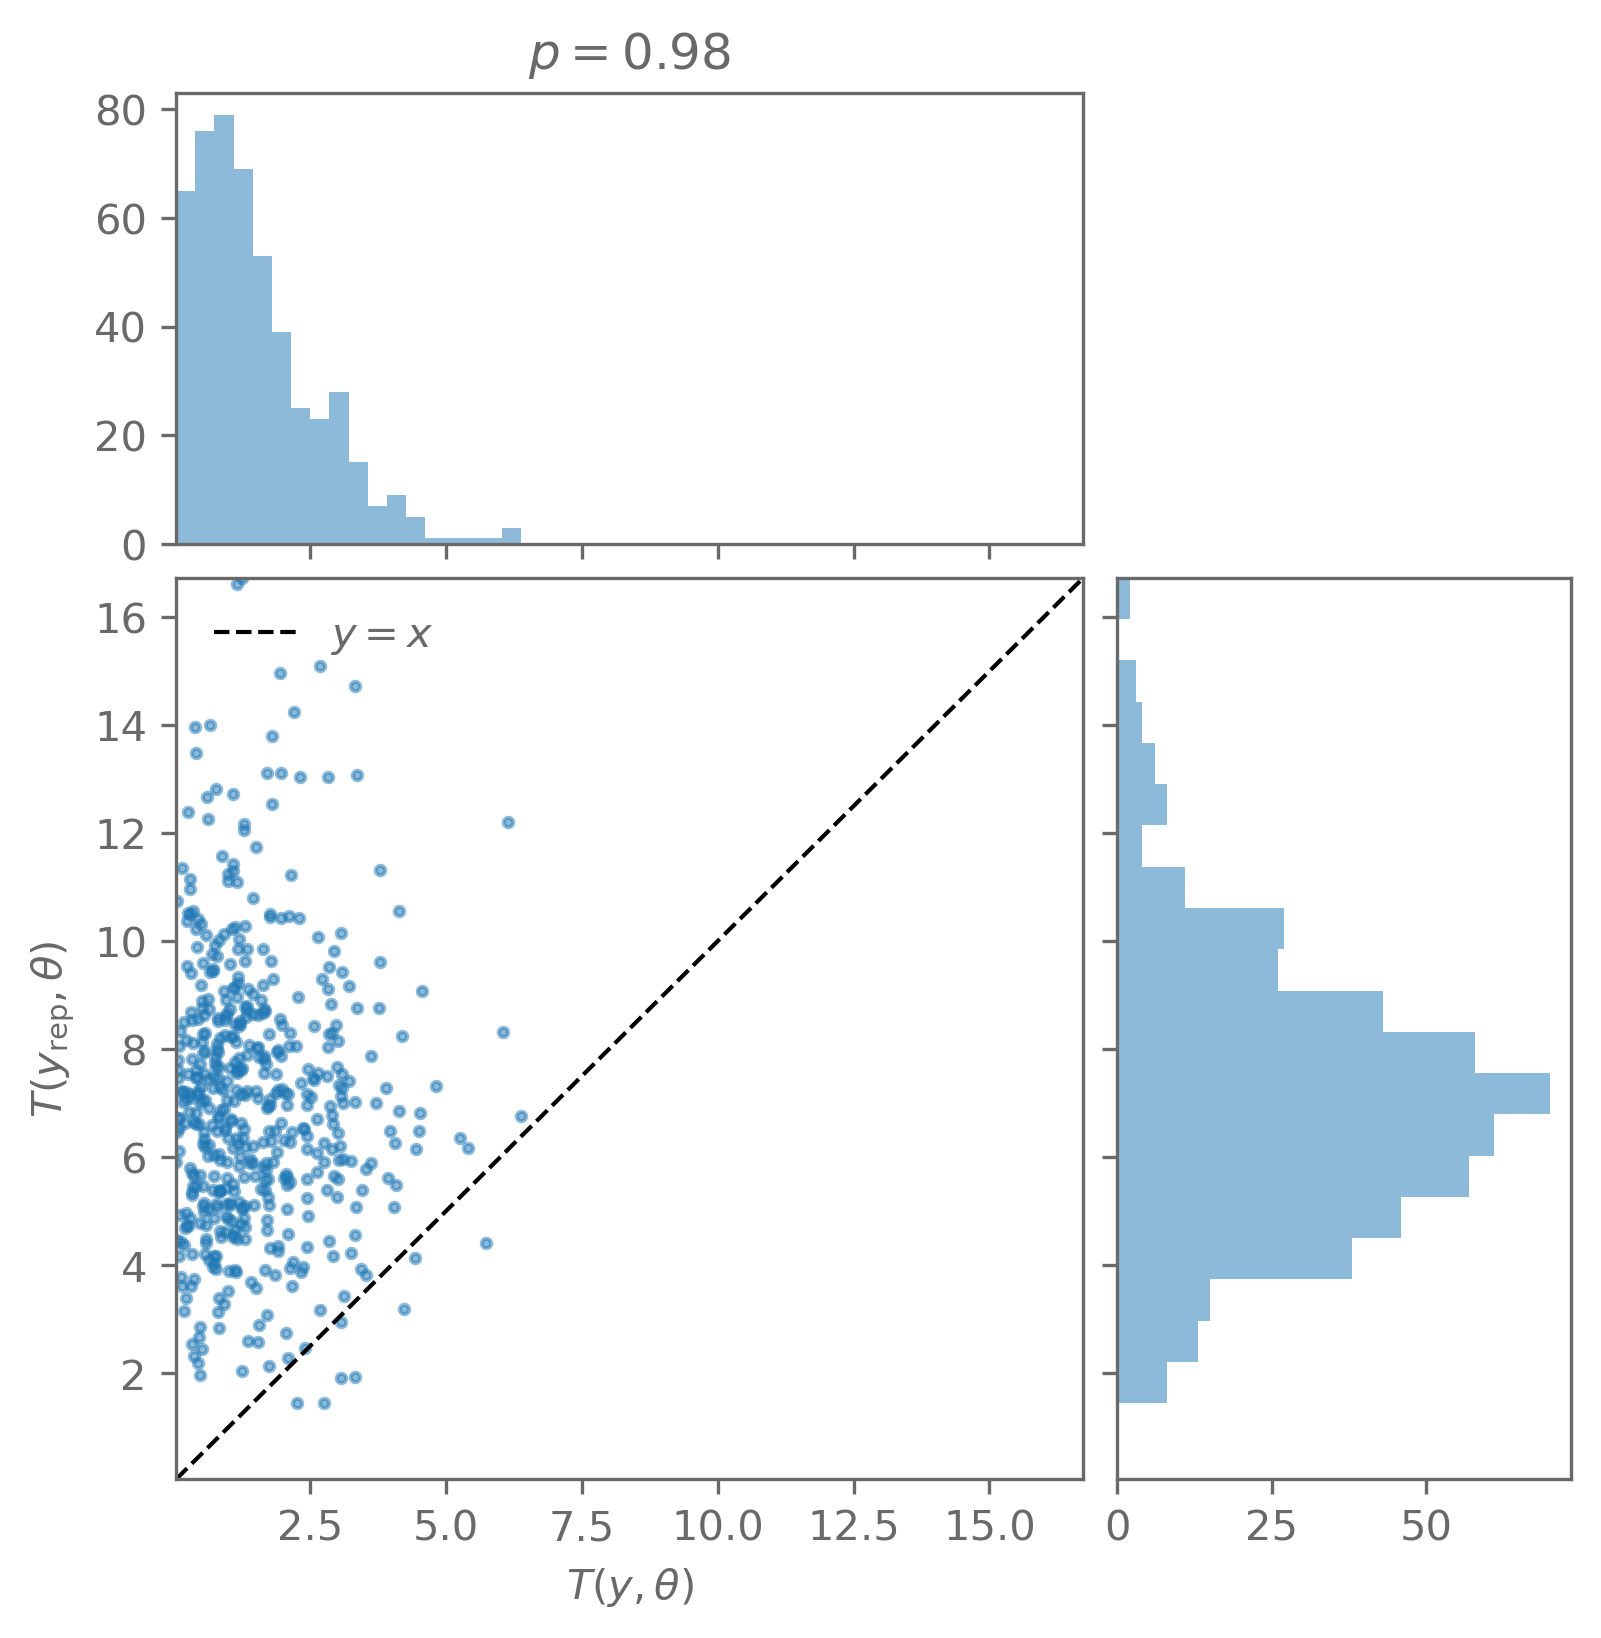

In [90]:
t_for_model = np.linspace(0, 90, 1000)

log_posterior, model, predict, ppd_test_statistic = build_inference_model(
    model_fn=base_model
)

data = dict(
    x=t, y=distance_alt, y_err=0.1
)

# derived parameter -- we want the mass based on the 
# measured semimajor axis and period. 
def mass_from_Kepler_3rd_law(theta):
    semimajor, period = theta[:2]
    return 4*(np.pi**2)/6.674e-11*((1e9*semimajor)**3)/((period*3600)**2)


results = analyse_data(
    data=data,
    log_posterior_fn=log_posterior,
    model_fn=model,
    predict_fn=predict,
    ppd_test_statistic_fn=ppd_test_statistic,
    param_names=["$a$", "$T$", "$\\phi$"],
    derived_parameter_fn=mass_from_Kepler_3rd_law,
    derived_parameter_names=["$M$"],
    derived_parameter_true=[1.8982e27],
    theta_true=theta_true[moon],
    theta_init=theta_true[moon],
    n_step_emcee=5000,
    model_x=t_for_model,
)